<a href="https://colab.research.google.com/github/cmd0850/machine_lerning/blob/main/%D0%9B%D0%912_%D0%B7%D0%B0%D0%B2%D0%B42_%D0%94%D0%B6%D0%B5%D0%BD%D1%87%D0%B0%D0%BA%D0%BE_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [102]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import kagglehub
import os

In [103]:
path=kagglehub.dataset_download('mahmoudshogaa/titanic-dataset')
print(path)

Using Colab cache for faster access to the 'titanic-dataset' dataset.
/kaggle/input/titanic-dataset


**PassengerId**: A unique identifier for each passenger.

**Survived**: This column indicates whether a passenger survived (1) or did not survive (0).

**Pclass (Ticket class)**: A proxy for socio-economic status, with 1 being the highest class and 3 the lowest.

**Name**: The name of the passenger.

**Sex**: The gender of the passenger.

**Age**: The age of the passenger. (Note: There might be missing values in this column.)

**SibSp**: The number of siblings or spouses the passenger had aboard the Titanic.

**Parch**: The number of parents or children the passenger had aboard the Titanic.

**Ticket**: The ticket number.

**Fare**: The amount of money the passenger paid for the ticket.

In [104]:
df=pd.read_csv(os.path.join(path, "titanic.csv"))
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [35]:
Визначити розмір датасета.
Визначити тип даних.

SyntaxError: invalid syntax (1089789846.py, line 1)

In [105]:
df.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


Визначити наявність пропущених значень. При наявності, замінити пропущені значення на середнє значення.

In [106]:
df.isna().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [107]:
df['Age']=df['Age'].fillna(df['Age'].mean())

df.drop('Cabin', axis=1, inplace=True)
df.drop('Embarked', axis=1, inplace=True)

In [108]:
df.isna().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [109]:
df.duplicated().sum()

np.int64(0)

Сформувати датасет з обраними стовпцями: ['Survived', 'Pclass', 'Sex', 'Age', 'Fare']]

In [110]:
df2=df[['Survived', 'Pclass', 'Sex', 'Age', 'Fare']]
df2

,Survived,Pclass,Sex,Age,Fare
0,0,3,male,22.000000,7.2500
1,1,1,female,38.000000,71.2833
2,1,3,female,26.000000,7.9250
3,1,1,female,35.000000,53.1000
4,0,3,male,35.000000,8.0500
...,...,...,...,...,...
886,0,2,male,27.000000,13.0000
887,1,1,female,19.000000,30.0000
888,0,3,female,29.699118,23.4500
889,1,1,male,26.000000,30.0000


In [ ]:
Замінити бінарні ознаки (Стать) на 0 і 1 (але перевірте унікальні значення даного стовпчика). Буває, що є середня стать)

In [111]:
df['Sex'].value_counts()

,count
Sex,
male,577
female,314


In [112]:
df['Sex']=df['Sex'].map({'male':1, 'female': 0})

In [113]:
df.isna().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [114]:
df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare
886,887,0,2,"Montvila, Rev. Juozas",1,27.000000,0,0,211536,13.00
887,888,1,1,"Graham, Miss. Margaret Edith",0,19.000000,0,0,112053,30.00
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",0,29.699118,1,2,W./C. 6607,23.45
889,890,1,1,"Behr, Mr. Karl Howell",1,26.000000,0,0,111369,30.00
890,891,0,3,"Dooley, Mr. Patrick",1,32.000000,0,0,370376,7.75


In [115]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500


Аналіз виживання залежно від статі: Обчисліть відсоток виживання для кожної статі. Чи була різниця у виживанні між чоловіками та жінками?

In [116]:
df.groupby('Sex')['Survived'].mean()

,Survived
Sex,
0,0.742038
1,0.188908


Тобто, вижило значно більше жінок ніж чоловіків.

Обчисліть відсоток виживання для кожного класу (Pclass). Який клас мав найвищий рівень виживання (дати відповідь)?

In [117]:
df.groupby('Pclass')['Survived'].mean()

,Survived
Pclass,
1,0.629630
2,0.472826
3,0.242363


Тобто, більше всього вижило людей з першого класу

Визначте середній вік тих, хто вижив, і тих, хто не вижив. Чи впливає вік на виживання (дати відповідь)?

In [118]:
survived_age=df[df['Survived']==1]['Age'].mean()
not_survived_age=df[df['Survived']==0]['Age'].mean()

print('Середній вік виживших:', survived_age, '\nСередній вік померлих: ', not_survived_age)

Середній вік виживших: 28.549778121775027 
Середній вік померлих:  30.415099646415943


Як можемо побачити, вік майже не вплинув на виживання

Розподіліть пасажирів на групи за рівнями тарифів (Fare) і обчисліть рівень виживання для кожної групи. Як тариф впливав на шанси виживання (дати відповідь)?

In [119]:
df['Fares']=pd.qcut(df['Fare'], 6, labels=False)

df.groupby('Fares')['Survived'].mean()


,Survived
Fares,
0,0.205128
1,0.190789
2,0.366906
3,0.436242
4,0.417808
5,0.697987


Як можемо побачити, чим більший був тариф тим значно вищі були шанси на виживання.

Аналіз класу та тарифу: Визначте середній тариф (Fare) для кожного класу (Pclass). Чи існує значна різниця у тарифах між класами (дати відповідь)?

In [120]:
df.groupby('Pclass')['Fare'].mean()

,Fare
Pclass,
1,84.154687
2,20.662183
3,13.675550


Дійсно, чим вищій клас, тим вищій тариф. Причому різниця між 1 класом та іншими колосальна

Як пов'язано середній вік пасажирів з виживанням? Відповідь дати аналітично чи графічно

/tmp/ipykernel_439/1170901506.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  survival = df.groupby('AgeGroup')['Survived'].mean() * 100


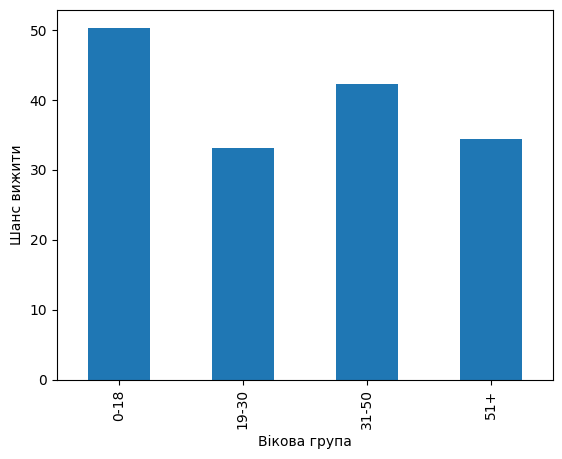

In [121]:
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[0, 18, 30, 50, 100],
    labels=['0-18', '19-30', '31-50', '51+']
)

survival = df.groupby('AgeGroup')['Survived'].mean() * 100

survival.plot(kind='bar')

plt.xlabel('Вікова група')
plt.ylabel('Шанс вижити')
plt.show()

Clalculate survival rate per class per sex теплову мапу

Sex  Pclass
0    1         96.808511
     2         92.105263
     3         50.000000
1    1         36.885246
     2         15.740741
     3         13.544669
Name: Survived, dtype: float64


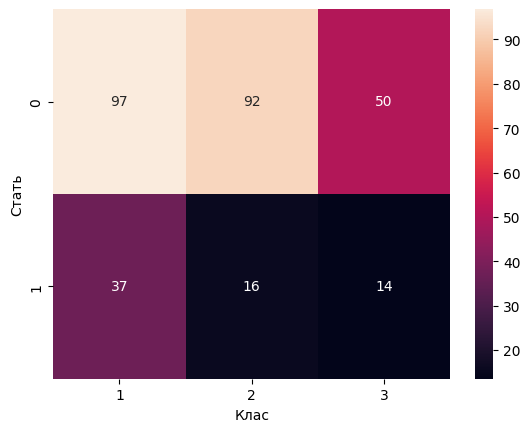

In [124]:

survival = df.groupby(['Sex', 'Pclass'])['Survived'].mean() * 100
print(survival)
survival=survival.unstack()

sns.heatmap(
            survival,
            annot=True,
            )

plt.xlabel('Клас')
plt.ylabel('Стать')
plt.show()

Як бачимо, кореляція між статтю, класом та шансом на виживання дуже велика. Жінки мали набагато більший шанс на виживання навіть знаходячись нижче по класу